# SQL analysis on the star schema

**Data:** the star schema built by `python -m procurement.pipeline` (step 6): `fact_award` (3,557,158 TED award records), `fact_world_bank_contract` (142,870 rows) and five shared dimensions. Every finding is written directly below the output it comes from.

**Key findings** (section numbers in brackets)

1. **Single bidding rose in 22 of 33 countries between 2019 and 2022** (competitive procedures). Poland (51.9%), Czechia (50.7%) and Slovenia (50.2%) had the highest rates in 2022 (2).
2. **201 buyers with 100+ awards have a single-bid rate of 80% or more**; 124 of them are in Slovenia, and 80 of those (64.5%) are schools or kindergartens (3).
3. **13.1% of buyers have highly concentrated spending** (HHI of 2,500 or more); in 603 buyers a single vendor receives over half of the value (4).
4. **4,459 buyer-vendor pairs share 20+ single-bid wins**, 190,038 single-bid awards in total (5).
5. **Sectors are mostly fragmented:** the three largest vendors take a median 9.6% of a sector's spending (6).
6. **0.82% of priced awards (16,911) are far above similar contracts** on a log-scale outlier rule, most often in transport services (2.9%) (7).
7. **672 companies win in both markets**, including COVID-19 vaccine makers that appear in both datasets (8).

Value-based results exclude framework agreements, whose published value is a ceiling rather than spending. All results are risk indicators and descriptions, not evidence of wrongdoing.

## 0. Setup

Run `python -m procurement.pipeline` first (step 6 builds the star schema). Every analysis below is a standalone file in `sql/analysis/`: the notebook prints the SQL, runs it, and shows the result. You can also run any of these files directly in DuckDB.

In [1]:
# Make the project package importable whether the notebook runs from the
# project root (VS Code default) or from the notebooks/ folder.
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
from IPython.display import Markdown, display

from procurement import config
from procurement.analysis import run_analysis

connection = duckdb.connect(str(config.DATABASE_PATH), read_only=True)


def query(sql):
    return connection.sql(sql).df()


def show_sql(name):
    """Display the SQL file behind an analysis, so the query can be read next to its result."""
    sql_text = (config.ANALYSIS_SQL_DIR / f"{name}.sql").read_text()
    display(Markdown(f"`sql/analysis/{name}.sql`\n```sql\n{sql_text}\n```"))


def as_percent(frame, columns, decimals=1):
    frame = frame.copy()
    for column in columns:
        frame[column] = frame[column].map(lambda value: "" if pd.isna(value) else f"{value:.{decimals}%}")
    return frame


BAR_COLOUR = "#2a78d6"
INCREASE_COLOUR = "#eb6834"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e0",
    "axes.edgecolor": "#b5b4ad", "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9,
})
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 30
pd.options.display.width = 220


def bar_chart(frame, label_column, value_column, title, xlabel, percent=False):
    frame = frame.sort_values(value_column)
    figure, axis = plt.subplots(figsize=(8, max(2.2, 0.32 * len(frame) + 0.8)))
    bars = axis.barh(frame[label_column].astype(str), frame[value_column], color=BAR_COLOUR, height=0.7)
    text_format = "{:.1%}" if percent else "{:,.0f}"
    for bar, value in zip(bars, frame[value_column]):
        axis.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, " " + text_format.format(value),
                  va="center", fontsize=8)
    if percent:
        axis.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
    axis.margins(x=0.12)
    axis.set_title(title, loc="left")
    axis.set_xlabel(xlabel)
    axis.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()

## 1. The star schema

One central **fact** table per source and shared **dimension** tables. Each fact row points to its dimensions through integer keys.

In [3]:
# The star schema: size of each table (built by sql/marts/, step 6 of the pipeline)
tables = ["fact_award", "fact_world_bank_contract", "dim_buyer", "dim_vendor",
          "dim_sector", "dim_procedure", "dim_date"]
query(" UNION ALL ".join(
    f"SELECT '{table}' AS table_name, COUNT(*) AS rows, (SELECT COUNT(*) FROM (DESCRIBE {table})) AS columns FROM {table}"
    for table in tables
))

,table_name,rows,columns
0,fact_award,3557158,19
1,fact_world_bank_contract,142870,11
2,dim_buyer,99679,7
3,dim_vendor,555443,9
4,dim_sector,45,3
5,dim_procedure,10,4
6,dim_date,1492,7


In [4]:
# One award, joined back to its dimensions: how the keys connect the star.
query("""
    SELECT
        fact.award_id, fact.date_key, dates.year, fact.buyer_key, buyer.buyer_name,
        buyer.buyer_country_name, fact.vendor_key, vendor.vendor_name, fact.sector_key,
        sector.sector_name, fact.procedure_key, procedure.procedure_type,
        fact.number_offers, fact.is_single_bid, fact.award_value_eur_plausible
    FROM fact_award AS fact
    JOIN dim_date      AS dates     ON fact.date_key = dates.date_key
    JOIN dim_buyer     AS buyer     ON fact.buyer_key = buyer.buyer_key
    JOIN dim_vendor    AS vendor    ON fact.vendor_key = vendor.vendor_key
    JOIN dim_sector    AS sector    ON fact.sector_key = sector.sector_key
    JOIN dim_procedure AS procedure ON fact.procedure_key = procedure.procedure_key
    WHERE fact.award_id = 12471400
""").T

,0
award_id,12471400
date_key,20210120
year,2021
buyer_key,52681
buyer_name,DEAL de Guyane
buyer_country_name,France
vendor_key,202777
vendor_name,Artelia
sector_key,71
sector_name,"Architectural, construction, engineering and i..."


**Finding.** The star schema has two fact tables and five dimensions: `fact_award` (3,557,158 rows, 19 columns), `fact_world_bank_contract` (142,870 rows), `dim_buyer` (99,679 buyers), `dim_vendor` (555,443 companies, shared by both facts), `dim_sector` (45), `dim_procedure` (10) and `dim_date` (1,492 days). The example shows one award resolved through its keys: `buyer_key` 52681 is DEAL de Guyane (France), `vendor_key` 202777 is Artelia, `sector_key` 71 is architectural and engineering services, and the procedure is Open. The fact table stores only keys and measures; the descriptions live once in the dimensions.

## 2. How does the single-bid rate change over time in each country?

Technique: `GROUP BY` + `LAG()` window function.

In [5]:
show_sql("01_single_bid_trend_by_country")
trend = run_analysis(connection, "01_single_bid_trend_by_country")
trend.head(8)

`sql/analysis/01_single_bid_trend_by_country.sql`
```sql
-- Q1. How does the single-bid rate change year by year in each country?
-- Scope: competitive procedures, awards with a known number of offers.
-- Technique: GROUP BY, then LAG() to compare each year with the previous one.
WITH yearly AS (
    SELECT
        buyer.buyer_country_name    AS country,
        dates.year,
        COUNT(*)                    AS labelled_awards,
        AVG(fact.is_single_bid)     AS single_bid_rate
    FROM fact_award AS fact
    JOIN dim_buyer     AS buyer     ON fact.buyer_key = buyer.buyer_key
    JOIN dim_date      AS dates     ON fact.date_key = dates.date_key
    JOIN dim_procedure AS procedure ON fact.procedure_key = procedure.procedure_key
    WHERE fact.is_single_bid IS NOT NULL
      AND procedure.is_competitive
      AND dates.year BETWEEN 2019 AND 2022      -- a few notices dispatched in Dec 2018 are excluded
    GROUP BY buyer.buyer_country_name, dates.year
)
SELECT
    country,
    year,
    labelled_awards,
    single_bid_rate,
    single_bid_rate - LAG(single_bid_rate) OVER (PARTITION BY country ORDER BY year)
        AS change_vs_previous_year
FROM yearly
ORDER BY country, year;

```

,country,year,labelled_awards,single_bid_rate,change_vs_previous_year
0,Austria,2019,4151,0.23,NaN
1,Austria,2020,4809,0.19,-0.04
2,Austria,2021,5250,0.22,0.03
3,Austria,2022,4822,0.27,0.05
4,Belgium,2019,8325,0.22,NaN
5,Belgium,2020,7543,0.21,-0.02
6,Belgium,2021,6939,0.22,0.01
7,Belgium,2022,6799,0.23,0.02


In [6]:
# Single-bid rate per country (rows) and year (columns), competitive procedures
pivot = trend.pivot(index="country", columns="year", values="single_bid_rate")
pivot["change_2019_2022"] = pivot[2022] - pivot[2019]
pivot = pivot.sort_values(2022, ascending=False)
as_percent(pivot.reset_index(), [2019, 2020, 2021, 2022, "change_2019_2022"])

year,country,2019,2020,2021,2022,change_2019_2022
0,Poland,51.0%,50.2%,49.8%,51.9%,0.8%
1,Czechia,51.4%,47.7%,48.6%,50.7%,-0.8%
2,Slovenia,61.1%,60.8%,60.8%,50.2%,-10.9%
3,Greece,41.2%,41.2%,39.4%,48.1%,6.9%
4,Hungary,41.2%,39.7%,40.6%,38.9%,-2.3%
5,Bulgaria,28.8%,27.7%,28.3%,34.8%,6.0%
6,Lithuania,25.9%,23.9%,28.4%,34.6%,8.7%
7,Italy,31.0%,29.0%,32.3%,34.0%,3.0%
8,Latvia,21.5%,18.5%,28.9%,31.3%,9.8%
9,Slovakia,29.8%,29.9%,28.8%,31.3%,1.5%


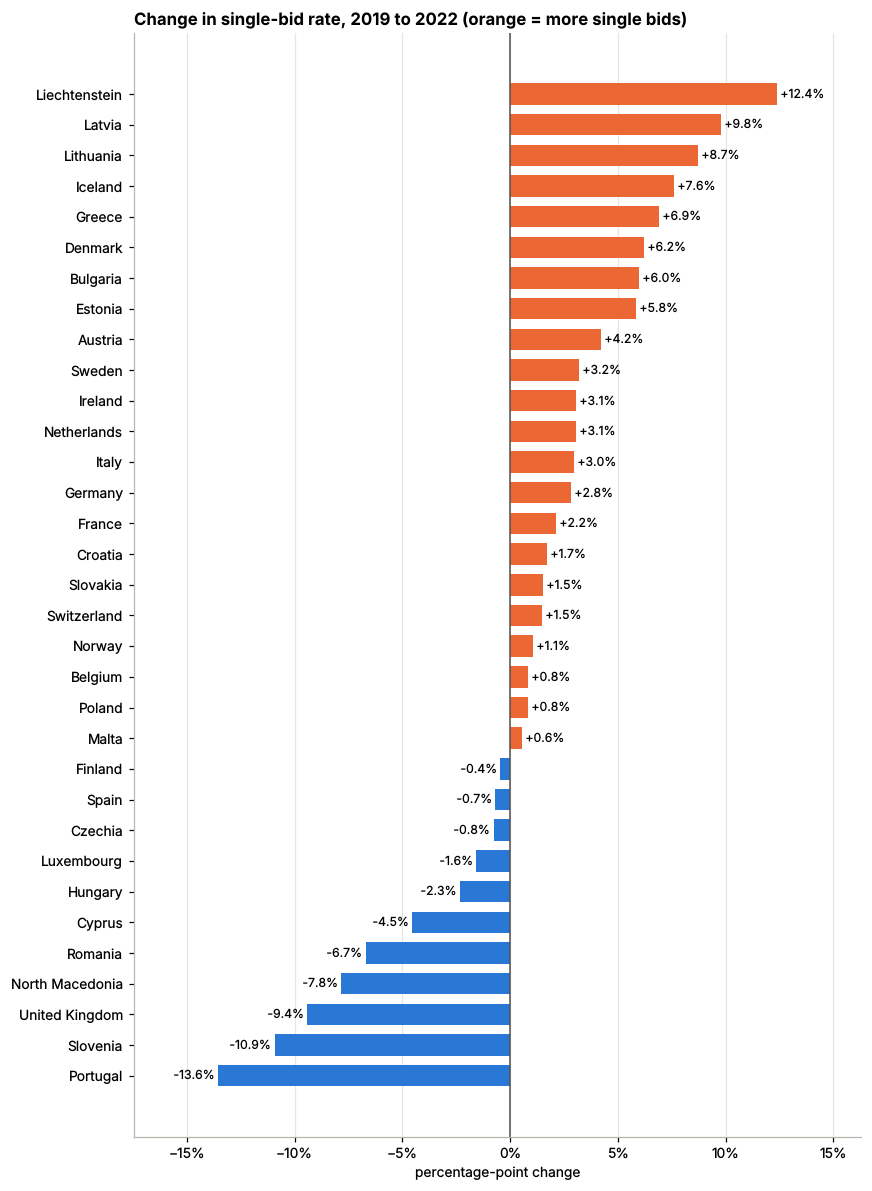

Countries with more single bids in 2022 than in 2019: 22 of 33


In [7]:
change = pivot["change_2019_2022"].dropna().sort_values()
figure, axis = plt.subplots(figsize=(8, 0.3 * len(change) + 1))
colours = [INCREASE_COLOUR if value > 0 else BAR_COLOUR for value in change]
bars = axis.barh(change.index, change.values, color=colours, height=0.7)
for bar, value in zip(bars, change.values):
    axis.text(value, bar.get_y() + bar.get_height() / 2, f" {value:+.1%} ",
              va="center", ha="left" if value > 0 else "right", fontsize=8)
axis.axvline(0, color="#52514e", linewidth=1)
axis.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
axis.margins(x=0.15)
axis.grid(axis="y", visible=False)
axis.set_title("Change in single-bid rate, 2019 to 2022 (orange = more single bids)", loc="left")
axis.set_xlabel("percentage-point change")
plt.tight_layout()
plt.show()
print(f"Countries with more single bids in 2022 than in 2019: {(change > 0).sum()} of {len(change)}")

**Findings** (competitive procedures).
- **2022 ranking:** Poland 51.9%, Czechia 50.7%, Slovenia 50.2% and Greece 48.1% are the highest; Sweden (10.9%), Ireland (11.1%) and Finland (11.1%) the lowest.
- **22 of 33 countries** had more single bids in 2022 than in 2019. The largest increases are Liechtenstein (+12.4 points, a very small market), Latvia (+9.8), Lithuania (+8.7) and Iceland (+7.6).
- **The largest decreases** are Portugal (-13.6 points), Slovenia (-10.9, falling from 61.1% to 50.2% in 2022 alone) and the United Kingdom (-9.4).
- Several large countries jumped in 2022, for example Germany from 19.4% to 24.9% and France from 17.2% to 20.3%. Whether this reflects market conditions in 2022 (such as supply shortages and price inflation) cannot be concluded from this data alone.

## 3. Which buyers have the highest single-bid rates?

Technique: CTEs, `HAVING`, `RANK()` overall and within each country. A high rate is a risk indicator worth a closer look, not evidence of wrongdoing.

In [8]:
show_sql("02_buyer_red_flags")
red_flags = run_analysis(connection, "02_buyer_red_flags")
summary = pd.DataFrame([{
    "buyers_with_100_plus_awards": len(red_flags),
    "buyers_at_100_percent": (red_flags["single_bid_rate"] == 1).sum(),
    "buyers_at_80_percent_or_more": (red_flags["single_bid_rate"] >= 0.8).sum(),
    "buyers_at_least_20_points_above_country": (red_flags["gap_vs_country"] >= 0.20).sum(),
}])
summary

`sql/analysis/02_buyer_red_flags.sql`
```sql
-- Q2. Which buyers have the highest single-bid rates? (an auditor's starting list)
-- Scope: competitive procedures; buyers with at least 100 labelled awards, so
-- that a rate is not driven by a handful of contracts.
-- Technique: CTEs, HAVING, RANK() overall and within each country.
-- A high rate is a risk indicator worth a closer look, not evidence of wrongdoing.
WITH competitive_awards AS (
    SELECT fact.buyer_key, fact.is_single_bid
    FROM fact_award AS fact
    JOIN dim_procedure AS procedure ON fact.procedure_key = procedure.procedure_key
    WHERE fact.is_single_bid IS NOT NULL
      AND procedure.is_competitive
),
buyer_rates AS (
    SELECT buyer_key, COUNT(*) AS labelled_awards, AVG(is_single_bid) AS single_bid_rate
    FROM competitive_awards
    GROUP BY buyer_key
    HAVING COUNT(*) >= 100
),
country_rates AS (
    SELECT buyer.buyer_country, AVG(awards.is_single_bid) AS country_rate
    FROM competitive_awards AS awards
    JOIN dim_buyer AS buyer ON awards.buyer_key = buyer.buyer_key
    GROUP BY buyer.buyer_country
)
SELECT
    RANK() OVER (ORDER BY rates.single_bid_rate DESC, rates.labelled_awards DESC) AS overall_rank,
    RANK() OVER (PARTITION BY buyer.buyer_country
                 ORDER BY rates.single_bid_rate DESC, rates.labelled_awards DESC) AS rank_in_country,
    buyer.buyer_name,
    buyer.buyer_country_name                                    AS country,
    buyer.buyer_type,
    rates.labelled_awards,
    rates.single_bid_rate,
    countries.country_rate,
    rates.single_bid_rate - countries.country_rate              AS gap_vs_country
FROM buyer_rates AS rates
JOIN dim_buyer     AS buyer     ON rates.buyer_key = buyer.buyer_key
JOIN country_rates AS countries ON buyer.buyer_country = countries.buyer_country
ORDER BY overall_rank;

```

,buyers_with_100_plus_awards,buyers_at_100_percent,buyers_at_80_percent_or_more,buyers_at_least_20_points_above_country
0,4573,6,201,497


In [9]:
as_percent(red_flags.head(10)[["overall_rank", "buyer_name", "country", "buyer_type",
                               "labelled_awards", "single_bid_rate", "country_rate", "gap_vs_country"]],
           ["single_bid_rate", "country_rate", "gap_vs_country"])

,overall_rank,buyer_name,country,buyer_type,labelled_awards,single_bid_rate,country_rate,gap_vs_country
0,1,Osnovna šola 8 talcev Logatec,Slovenia,Body governed by public law,190,100.0%,59.7%,40.3%
1,2,ΠΕΡΙΦΕΡΕΙΑ ΠΕΛΟΠΟΝΝΗΣΟΥ Π.Ε. ΜΕΣΣΗΝΙΑΣ,Greece,Regional or local authority,151,100.0%,42.8%,57.2%
2,3,Osnovna šola Cankova,Slovenia,Body governed by public law,144,100.0%,59.7%,40.3%
3,4,SVMS — Secondary Vocational Municipal School K...,North Macedonia,Regional or local authority,120,100.0%,25.7%,74.3%
4,5,"Osnovna šola Ivana Skvarče Zagorje ob Savi, C....",Slovenia,Body governed by public law,119,100.0%,59.7%,40.3%
5,6,Osnovna šola Milojke Štrukelj Nova Gorica,Slovenia,National authority,107,100.0%,59.7%,40.3%
6,7,Győr Megyei Jogú Város Útkezelő Szervezete,Hungary,Other,820,99.6%,40.0%,59.7%
7,8,Festival Ljubljana,Slovenia,Regional or local authority,291,99.3%,59.7%,39.6%
8,9,AOK Bremen/Bremerhaven,Germany,Body governed by public law,356,99.2%,21.6%,77.6%
9,10,Ministerstvo obrany - Česká republika; Sekce n...,Czechia,National authority,230,99.1%,49.6%,49.5%


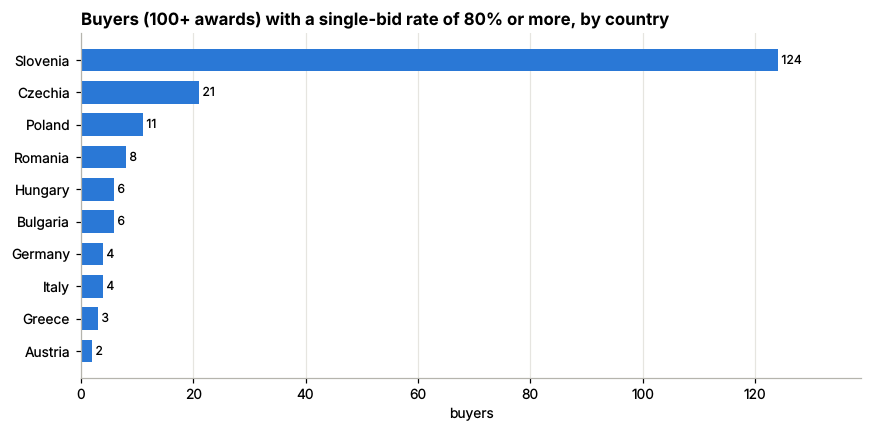

,country,buyers_at_80_percent_or_more
17,Slovenia,124
3,Czechia,21
13,Poland,11
15,Romania,8
2,Bulgaria,6
7,Hungary,6
8,Italy,4
5,Germany,4
6,Greece,3
0,Austria,2


In [10]:
flagged_by_country = (red_flags[red_flags["single_bid_rate"] >= 0.8]
                      .groupby("country").size().reset_index(name="buyers_at_80_percent_or_more")
                      .sort_values("buyers_at_80_percent_or_more", ascending=False).head(10))
bar_chart(flagged_by_country, "country", "buyers_at_80_percent_or_more",
          "Buyers (100+ awards) with a single-bid rate of 80% or more, by country", "buyers")
flagged_by_country

In [11]:
# Slovenia has by far the most buyers at 80%+. What kind of buyers are they?
# 'osnovna šola' = primary school, 'vrtec' = kindergarten (names in Slovenian).
slovenia = red_flags[(red_flags["country"] == "Slovenia") & (red_flags["single_bid_rate"] >= 0.8)]
is_school = slovenia["buyer_name"].str.lower().str.contains("osnovna šola|vrtec|gimnazija|srednja šola")
pd.DataFrame([{
    "slovenian_buyers_at_80_percent_or_more": len(slovenia),
    "of_which_schools_or_kindergartens": int(is_school.sum()),
    "share": is_school.mean(),
}]).pipe(as_percent, ["share"])

,slovenian_buyers_at_80_percent_or_more,of_which_schools_or_kindergartens,share
0,124,80,64.5%


**Findings.**
- 4,573 buyers have at least 100 labelled competitive awards. 6 of them received a single offer in **every** award, 201 have a rate of 80% or more, and 497 are at least 20 points above their country's average.
- **Slovenia accounts for 124 of the 201** buyers at 80% or more, far ahead of Czechia (21) and Poland (11). Of those 124, **80 (64.5%) are schools or kindergartens**. This points to a structural pattern (many small public schools running similar routine purchases that attract one supplier) rather than to individual buyers, and explains part of Slovenia's high national rate.
- The list mixes very different buyers (the road authority of the city of Győr in Hungary at 99.6% over 820 awards, a German statutory health insurer at 99.2%), so each name needs context before any conclusion.

## 4. How concentrated is each buyer's spending?

Technique: window functions for shares, then the Herfindahl-Hirschman Index (HHI = sum of squared market shares, 0 to 10,000).

`sql/analysis/03_buyer_concentration.sql`
```sql
-- Q3. How concentrated is each buyer's spending across vendors?
-- Scope: awarded contracts with a plausible value and a known winner; buyers
-- with at least 50 such awards.
-- Technique: CTEs + window functions (SUM() OVER) to compute each vendor's
-- share of a buyer's spending, then the Herfindahl-Hirschman Index (HHI):
--     HHI = sum over vendors of (share x 100)^2
-- It ranges from near 0 (spending spread over many vendors) to 10,000 (one
-- vendor gets everything). Competition authorities have long used 1,500 and
-- 2,500 as the bands for moderate and high concentration.
-- Framework agreements are excluded from value sums: their published value is a
-- ceiling for future orders, not actual spending (they are 18% of priced awards
-- but about half of all published value).
WITH buyer_vendor AS (
    SELECT
        buyer_key,
        vendor_key,
        COUNT(*)                        AS awards,
        SUM(award_value_eur_plausible)  AS value_eur
    FROM fact_award
    WHERE is_awarded = 1
      AND vendor_key IS NOT NULL
      AND award_value_eur_plausible IS NOT NULL
      AND NOT COALESCE(is_framework_agreement, FALSE)
    GROUP BY buyer_key, vendor_key
),
shares AS (
    SELECT
        buyer_key,
        awards,
        value_eur,
        value_eur / SUM(value_eur) OVER (PARTITION BY buyer_key) AS value_share
    FROM buyer_vendor
)
SELECT
    buyer.buyer_name,
    buyer.buyer_country_name             AS country,
    SUM(shares.awards)                   AS awards,
    COUNT(*)                             AS vendors,
    SUM(shares.value_eur)                AS total_value_eur,
    MAX(shares.value_share)              AS top_vendor_share,
    SUM(POWER(shares.value_share * 100, 2)) AS hhi,
    CASE
        WHEN SUM(POWER(shares.value_share * 100, 2)) >= 2500 THEN 'high'
        WHEN SUM(POWER(shares.value_share * 100, 2)) >= 1500 THEN 'moderate'
        ELSE 'low'
    END                                  AS concentration
FROM shares
JOIN dim_buyer AS buyer ON shares.buyer_key = buyer.buyer_key
GROUP BY buyer.buyer_key, buyer.buyer_name, buyer.buyer_country_name
HAVING SUM(shares.awards) >= 50
ORDER BY hhi DESC;

```

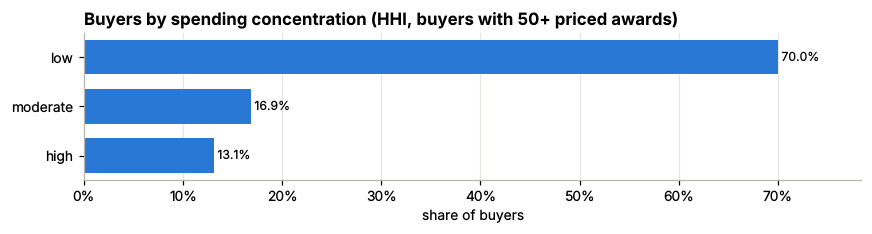

,concentration,buyers,share_of_buyers
0,high,846,13.1%
1,low,4511,70.0%
2,moderate,1086,16.9%


In [12]:
show_sql("03_buyer_concentration")
concentration = run_analysis(connection, "03_buyer_concentration")
bands = concentration.groupby("concentration").agg(buyers=("buyer_name", "size")).reset_index()
bands["share_of_buyers"] = bands["buyers"] / bands["buyers"].sum()
bar_chart(bands, "concentration", "share_of_buyers",
          "Buyers by spending concentration (HHI, buyers with 50+ priced awards)", "share of buyers", percent=True)
as_percent(bands, ["share_of_buyers"])

In [13]:
pd.DataFrame([{
    "buyers": len(concentration),
    "median_vendors_per_buyer": concentration["vendors"].median(),
    "median_top_vendor_share": concentration["top_vendor_share"].median(),
    "buyers_where_top_vendor_gets_over_half": (concentration["top_vendor_share"] > 0.5).sum(),
}]).pipe(as_percent, ["median_top_vendor_share"])

,buyers,median_vendors_per_buyer,median_top_vendor_share,buyers_where_top_vendor_gets_over_half
0,6443,50.00,21.6%,603


In [14]:
# Most concentrated buyers among those spending over EUR 10 million
large = concentration[concentration["total_value_eur"] > 10_000_000]
as_percent(large.head(10)[["buyer_name", "country", "awards", "vendors", "total_value_eur",
                           "top_vendor_share", "hhi"]], ["top_vendor_share"])

,buyer_name,country,awards,vendors,total_value_eur,top_vendor_share,hhi
2,Vrtec Kolezija,Slovenia,381.00,22,"31,374,882.29",99.2%,"9,840.31"
4,"""Zakład Gospodarki Komunalnej w Szamotułach"" S...",Poland,78.00,11,"63,802,953.45",99.0%,"9,796.84"
5,Centralne Laboratorium Kryminalistyczne Policji,Poland,74.00,26,"37,177,737.83",98.4%,"9,675.37"
7,Wojewódzki Szpital Specjalistyczny w Olsztynie,Poland,62.00,34,"439,674,337.83",98.1%,"9,630.09"
9,"Águas e Resíduos da Madeira (ARM), S. A.",Portugal,55.00,28,"399,269,038.03",97.1%,"9,430.87"
11,BIBLIOTEKA PUBLICZNA w Dzielnicy Ochota m. st....,Poland,65.00,4,"33,105,965.32",96.6%,"9,347.62"
12,Universitat Autònoma de Barcelona,Spain,52.00,39,"943,488,418.26",96.6%,"9,329.21"
14,Provincia di Macerata,Italy,73.00,66,"986,534,629.96",96.3%,"9,269.17"
15,SDEE de la Lozère,France,82.00,31,"624,056,136.00",96.1%,"9,245.13"
16,Veolia Energia Warszawa S.A.,Poland,251.00,42,"639,677,003.51",95.7%,"9,163.83"


**Findings** (non-framework awards with a plausible value; buyers with 50+ such awards).
- Of 6,443 buyers, **70.0%** have low concentration, **16.9%** moderate and **13.1%** high (HHI of 2,500 or more).
- The median buyer works with 50 vendors, and its largest vendor receives 21.6% of its spending. In **603 buyers** a single vendor receives more than half of the value.
- **Caution:** value-based concentration is sensitive to one large contract. For example, a regional hospital in Olsztyn (Poland) used 34 vendors, but one vendor received 98.1% of its EUR 439.7 million, most likely a single large project. High HHI identifies where to look; it does not by itself show restricted competition.

## 5. Which buyer-vendor pairs repeat single-bid wins?

Technique: aggregation on a pair of keys.

In [15]:
show_sql("04_repeat_single_bid_pairs")
pairs = run_analysis(connection, "04_repeat_single_bid_pairs")
pd.DataFrame([{
    "pairs_with_20_plus_single_bid_wins": len(pairs),
    "single_bid_awards_in_these_pairs": int(pairs["single_bid_awards"].sum()),
    "pairs_with_100_plus": (pairs["single_bid_awards"] >= 100).sum(),
    "median_single_bid_rate_of_pairs": pairs["single_bid_rate"].median(),
}]).pipe(as_percent, ["median_single_bid_rate_of_pairs"])

`sql/analysis/04_repeat_single_bid_pairs.sql`
```sql
-- Q4. Which buyer-vendor pairs repeat single-bid wins most often?
-- Scope: competitive procedures; pairs with at least 20 single-bid awards.
-- Technique: JOINs + aggregation on a pair of keys.
-- A frequent pair can have legitimate reasons (a specialised supplier, a niche
-- market); it is a pattern to examine, not a finding of wrongdoing.
SELECT
    buyer.buyer_name,
    buyer.buyer_country_name            AS buyer_country,
    vendor.vendor_name,
    vendor.vendor_country,
    COUNT(*)                            AS labelled_awards,
    SUM(fact.is_single_bid)             AS single_bid_awards,
    AVG(fact.is_single_bid)             AS single_bid_rate
FROM fact_award AS fact
JOIN dim_buyer     AS buyer     ON fact.buyer_key = buyer.buyer_key
JOIN dim_vendor    AS vendor    ON fact.vendor_key = vendor.vendor_key
JOIN dim_procedure AS procedure ON fact.procedure_key = procedure.procedure_key
WHERE fact.is_single_bid IS NOT NULL
  AND procedure.is_competitive
GROUP BY buyer.buyer_key, buyer.buyer_name, buyer.buyer_country_name,
         vendor.vendor_key, vendor.vendor_name, vendor.vendor_country
HAVING SUM(fact.is_single_bid) >= 20
ORDER BY single_bid_awards DESC;

```

,pairs_with_20_plus_single_bid_wins,single_bid_awards_in_these_pairs,pairs_with_100_plus,median_single_bid_rate_of_pairs
0,4459,190038,207,80.6%


In [16]:
# Vendor names are left out of this public notebook (some vendors are individuals);
# the full result is saved locally by `python -m procurement.analysis`.
as_percent(pairs.head(10)[["buyer_name", "buyer_country", "vendor_country",
                           "labelled_awards", "single_bid_awards", "single_bid_rate"]], ["single_bid_rate"])

,buyer_name,buyer_country,vendor_country,labelled_awards,single_bid_awards,single_bid_rate
0,Česká republika - Ministerstvo práce a sociáln...,Czechia,CZ,1753,"1,731.00",98.7%
1,Opus LGSS People Solutions Ltd,United Kingdom,UK,1194,"1,086.00",91.0%
2,Fakultní nemocnice Brno,Czechia,CZ,1373,968.00,70.5%
3,Fakultní nemocnice Brno,Czechia,CZ,1528,964.00,63.1%
4,Ministrstvo za javno upravo,Slovenia,SI,968,840.00,86.8%
5,Česká republika - Ministerstvo práce a sociáln...,Czechia,CZ,778,777.00,99.9%
6,Česká republika - Ministerstvo práce a sociáln...,Czechia,CZ,679,678.00,99.9%
7,Západočeská univerzita v Plzni,Czechia,CZ,771,657.00,85.2%
8,London Borough of Waltham Forest,United Kingdom,UK,661,647.00,97.9%
9,Győr Megyei Jogú Város Útkezelő Szervezete,Hungary,HU,547,547.00,100.0%


**Findings.**
- **4,459 buyer-vendor pairs** each share at least 20 single-bid wins, 190,038 single-bid awards in total; 207 pairs have 100 or more. The median pair wins 80.6% of its contracts as the only bidder.
- The largest pair links the Czech Ministry of Labour and Social Affairs to one vendor: 1,731 single-bid awards out of 1,753 (98.7%).
- Repeated single-bid wins can have ordinary causes (a specialised supplier, a long-running service split into many lots). Vendor names are omitted here; the full result is saved locally by `python -m procurement.analysis`.

## 6. Which vendors lead each sector?

Technique: `SUM() OVER (PARTITION BY ...)` + `ROW_NUMBER()`.

In [17]:
show_sql("05_sector_top_vendors")
top_vendors = run_analysis(connection, "05_sector_top_vendors")
leaders = top_vendors[top_vendors["vendor_rank"] == 1].sort_values("share_of_sector", ascending=False)
as_percent(leaders.head(10)[["sector_name", "vendor_name", "vendor_country", "value_eur", "share_of_sector"]],
           ["share_of_sector"])

`sql/analysis/05_sector_top_vendors.sql`
```sql
-- Q5. Which vendors win the largest share of each sector's spending?
-- Scope: awarded contracts with a plausible value and a known winner.
-- Technique: SUM() OVER (PARTITION BY sector) for shares, ROW_NUMBER() to keep
-- the top 3 vendors per sector.
-- Framework agreements are excluded from value sums: their published value is a
-- ceiling for future orders, not actual spending (they are 18% of priced awards
-- but about half of all published value).
WITH sector_vendor AS (
    SELECT
        sector_key,
        vendor_key,
        SUM(award_value_eur_plausible) AS value_eur
    FROM fact_award
    WHERE is_awarded = 1
      AND vendor_key IS NOT NULL
      AND award_value_eur_plausible IS NOT NULL
      AND NOT COALESCE(is_framework_agreement, FALSE)
    GROUP BY sector_key, vendor_key
),
ranked AS (
    SELECT
        sector_key,
        vendor_key,
        value_eur,
        value_eur / SUM(value_eur) OVER (PARTITION BY sector_key)      AS share_of_sector,
        ROW_NUMBER() OVER (PARTITION BY sector_key ORDER BY value_eur DESC) AS vendor_rank
    FROM sector_vendor
)
SELECT
    sector.sector_name,
    ranked.vendor_rank,
    vendor.vendor_name,
    vendor.vendor_country,
    ranked.value_eur,
    ranked.share_of_sector
FROM ranked
JOIN dim_sector AS sector ON ranked.sector_key = sector.sector_key
JOIN dim_vendor AS vendor ON ranked.vendor_key = vendor.vendor_key
WHERE ranked.vendor_rank <= 3
ORDER BY sector.sector_name, ranked.vendor_rank;

```

,sector_name,vendor_name,vendor_country,value_eur,share_of_sector
117,Services related to the oil and gas industry,Bonatti SPA,IT,"1,423,020,470.01",30.8%
24,Collected and purified water,"ČEZ, a.s.",CZ,"221,138,845.55",22.1%
93,Printed matter and related products,Atea Sverige AB,SE,"610,784,901.93",17.0%
78,"Musical instruments, sports goods, games, toys...",Brest'Aim,FR,"169,414,000.00",16.3%
69,"Machinery for mining, quarrying and constructi...",FAMUR S.A.,PL,"356,421,369.92",13.9%
96,Public utilities,Enedis,FR,"4,073,693,458.00",12.0%
84,"Other community, social and personal services",Mears Ltd,UK,"1,649,634,870.18",11.7%
60,Installation services,ESB Generation & Wholesale Markets,IE,"508,700,000.00",11.4%
111,Research and development services and related ...,BJL,UK,"398,737,710.33",7.9%
6,"Agricultural, farming, fishing, forestry and r...",Maelor Forest Nurseries Ltd,UK,"146,579,804.56",7.1%


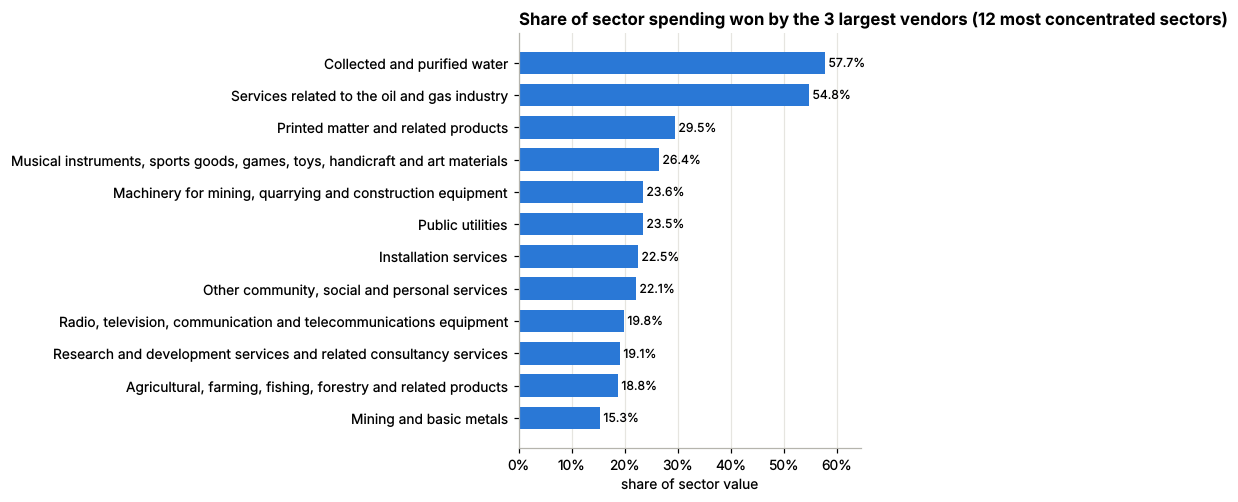

,sectors,median_top_3_share
0,45,9.6%


In [18]:
top3 = top_vendors.groupby("sector_name")["share_of_sector"].sum().reset_index(name="top_3_share")
top3 = top3.sort_values("top_3_share", ascending=False)
bar_chart(top3.head(12), "sector_name", "top_3_share",
          "Share of sector spending won by the 3 largest vendors (12 most concentrated sectors)",
          "share of sector value", percent=True)
pd.DataFrame([{"sectors": len(top3), "median_top_3_share": top3["top_3_share"].median()}]).pipe(as_percent, ["median_top_3_share"])

**Findings.**
- Across the 45 sectors, the three largest vendors take a **median 9.6%** of sector spending, so most public markets are fragmented across many suppliers.
- The most concentrated leaders are in specialised markets: Bonatti (Italy) holds 30.8% of services for the oil and gas industry, ČEZ (Czechia) 22.1% of collected and purified water, and Atea Sverige (Sweden) 17.0% of printed matter.
- Large utilities appear as expected: Enedis (France) receives 12.0% of public-utilities spending.

## 7. Which awards are priced far above similar contracts?

Technique: `QUANTILE_CONT() OVER (PARTITION BY ...)` and the Tukey outlier rule on a log scale.

`sql/analysis/06_price_anomalies.sql`
```sql
-- Q6. How many awards are priced far above similar contracts?
-- "Similar" = same sector, contract type and buyer country (groups of 30+ awards).
-- Contract values span several orders of magnitude, so the comparison is made on
-- a log scale, with the standard Tukey outlier rule:
--     anomaly if log10(value) > Q3 + 1.5 x IQR   (IQR = Q3 - Q1 of the group)
-- Technique: QUANTILE_CONT() OVER (PARTITION BY ...) compares each row with its group.
-- A high value can be legitimate (a genuinely larger contract); it is a signal for
-- review and a candidate feature for the anomaly model in Phase 5.
-- Framework agreements are excluded from value sums: their published value is a
-- ceiling for future orders, not actual spending (they are 18% of priced awards
-- but about half of all published value).
WITH priced AS (
    SELECT
        fact.sector_key,
        LOG10(fact.award_value_eur_plausible)                          AS log_value,
        QUANTILE_CONT(LOG10(fact.award_value_eur_plausible), 0.25) OVER group_window AS group_q1,
        QUANTILE_CONT(LOG10(fact.award_value_eur_plausible), 0.75) OVER group_window AS group_q3,
        COUNT(*) OVER group_window                                     AS group_awards
    FROM fact_award AS fact
    JOIN dim_buyer AS buyer ON fact.buyer_key = buyer.buyer_key
    WHERE fact.is_awarded = 1
      AND fact.award_value_eur_plausible IS NOT NULL
      AND NOT COALESCE(fact.is_framework_agreement, FALSE)
    WINDOW group_window AS (PARTITION BY fact.sector_key, fact.contract_type, buyer.buyer_country)
),
flagged AS (
    SELECT
        sector_key,
        log_value > group_q3 + 1.5 * (group_q3 - group_q1) AS is_anomaly
    FROM priced
    WHERE group_awards >= 30
)
SELECT
    sector.sector_name,
    COUNT(*)                                             AS awards,
    SUM(CASE WHEN is_anomaly THEN 1 ELSE 0 END)          AS anomalies,
    AVG(CASE WHEN is_anomaly THEN 1.0 ELSE 0.0 END)      AS anomaly_share
FROM flagged
JOIN dim_sector AS sector ON flagged.sector_key = sector.sector_key
GROUP BY sector.sector_name
ORDER BY anomaly_share DESC;

```

,priced_awards_checked,anomalies,anomaly_share
0,2073875,16911,0.82%


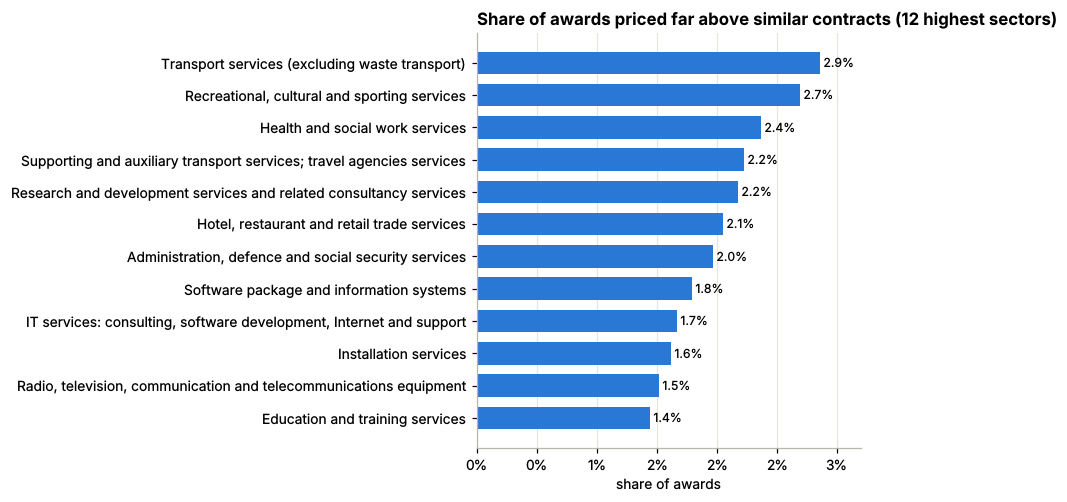

,sector_name,awards,anomalies,anomaly_share
0,Transport services (excluding waste transport),57750,"1,653.00",2.9%
1,"Recreational, cultural and sporting services",7611,205.00,2.7%
2,Health and social work services,39966,948.00,2.4%
3,Supporting and auxiliary transport services; t...,5612,125.00,2.2%
4,Research and development services and related ...,5091,111.00,2.2%
5,"Hotel, restaurant and retail trade services",12375,254.00,2.1%
6,"Administration, defence and social security se...",4475,88.00,2.0%
7,Software package and information systems,18320,329.00,1.8%
8,"IT services: consulting, software development,...",38203,637.00,1.7%
9,Installation services,1850,30.00,1.6%


In [19]:
show_sql("06_price_anomalies")
anomalies = run_analysis(connection, "06_price_anomalies")
overall = pd.DataFrame([{
    "priced_awards_checked": int(anomalies["awards"].sum()),
    "anomalies": int(anomalies["anomalies"].sum()),
    "anomaly_share": anomalies["anomalies"].sum() / anomalies["awards"].sum(),
}])
display(as_percent(overall, ["anomaly_share"], decimals=2))
bar_chart(anomalies.head(12), "sector_name", "anomaly_share",
          "Share of awards priced far above similar contracts (12 highest sectors)", "share of awards", percent=True)
as_percent(anomalies.head(12), ["anomaly_share"])

**Findings.**
- 2,073,875 priced, non-framework awards were compared with their group (same sector, contract type and country). **16,911 (0.82%)** are above the log-scale Tukey threshold.
- The highest shares are in transport services (2.9%), recreational, cultural and sporting services (2.7%) and health and social work services (2.4%).
- These are candidates for review and a feature for the Phase 5 anomaly model. A flagged award can be a genuinely large contract.

## 8. Which companies win in both markets?

Technique: one dimension shared by two fact tables.

In [20]:
show_sql("07_cross_market_vendors")
cross_market = run_analysis(connection, "07_cross_market_vendors")
print(f"{len(cross_market):,} companies won both EU tenders and World Bank contracts")
cross_market.head(10)

`sql/analysis/07_cross_market_vendors.sql`
```sql
-- Q7. Which companies win both EU tenders and World Bank contracts, and how much?
-- Technique: one dimension (dim_vendor) shared by two fact tables. Each fact is
-- aggregated per vendor first, then joined, which avoids multiplying rows.
-- Framework agreements are excluded from value sums: their published value is a
-- ceiling for future orders, not actual spending (they are 18% of priced awards
-- but about half of all published value).
WITH eu AS (
    SELECT
        vendor_key,
        COUNT(*) AS eu_awards,
        SUM(CASE WHEN NOT COALESCE(is_framework_agreement, FALSE)
                 THEN award_value_eur_plausible END) AS eu_value_eur
    FROM fact_award
    WHERE is_awarded = 1
    GROUP BY vendor_key
),
world_bank AS (
    SELECT vendor_key, COUNT(DISTINCT contract_id) AS world_bank_contracts,
           SUM(amount_usd_for_totals) AS world_bank_value_usd
    FROM fact_world_bank_contract
    GROUP BY vendor_key
)
SELECT
    vendor.vendor_name,
    vendor.vendor_country,
    eu.eu_awards,
    eu.eu_value_eur,
    world_bank.world_bank_contracts,
    world_bank.world_bank_value_usd
FROM dim_vendor AS vendor
JOIN eu         ON vendor.vendor_key = eu.vendor_key
JOIN world_bank ON vendor.vendor_key = world_bank.vendor_key
WHERE vendor.in_ted AND vendor.in_world_bank
ORDER BY world_bank.world_bank_value_usd DESC;

```

672 companies won both EU tenders and World Bank contracts


,vendor_name,vendor_country,eu_awards,eu_value_eur,world_bank_contracts,world_bank_value_usd
0,Moderna Switzerland GmbH,CH,4,"2,527,904.10",3,"788,361,000.00"
1,Sinohydro Corporation Limited,CN,3,"803,720,138.65",41,"785,101,992.71"
2,BioNTech Manufacturing GmbH,DE,3,NaN,2,"749,445,307.00"
3,"Acciona Agua, S. A.",ES,26,"280,171,721.54",1,"251,207,832.33"
4,Pfizer Export B.V.,NL,24,"29,651,310.00",5,"174,698,852.00"
5,"Pinggao Group Co., ltd",CN,1,"1,433,346.80",2,"157,041,326.54"
6,KEC International Ltd,IN,1,NaN,5,"105,325,290.83"
7,Skanska S.A.,PL,34,"322,907,637.53",6,"86,811,040.07"
8,"Boskalis International, B.V.",NL,1,"17,443,880.00",1,"62,526,097.27"
9,KOLİN İNŞAAT TURİZM SANAYİ VE TİCARET ANONİM Ş...,TR,2,"264,936,506.22",1,"61,963,827.37"


**Findings.**
- **672 companies** won both EU tenders and World Bank contracts.
- The largest by World Bank value include COVID-19 vaccine makers (Moderna Switzerland: USD 788 million in World Bank contracts and 4 EU awards; BioNTech Manufacturing: USD 749 million), and contractors active in both markets such as Sinohydro (41 World Bank contracts) and Skanska S.A. (Poland: 34 EU awards worth EUR 323 million and 6 World Bank contracts).
- This link is only possible because both fact tables share `dim_vendor`.

## 9. Conclusions and next steps

| Result | Use in later phases |
|---|---|
| Star schema in `data/marts/` (7 Parquet tables) | **Phase 4:** loaded into Power BI with relationships fact → dimensions |
| Single-bid rates by country, year, buyer, pair | Power BI pages for competition and red flags |
| Buyer concentration (HHI) and sector leaders | Power BI page for vendor concentration |
| Strong buyer-level patterns (e.g. Slovenian schools) | **Phase 5:** buyer history as a feature, computed only from earlier awards to avoid leakage |
| Log-scale price outliers (0.82%) | **Phase 5:** starting point for the price anomaly model |
| Framework values are ceilings, not spending | All value analyses exclude framework agreements |

In [21]:
connection.close()